In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'
import Funciones as Funciones
from NNMF_GIF import NNMF_GIF 
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF

In [2]:
FC = FileChooser('Señales AC3E/Femenino')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [4]:
norma='frobenius'


archivo = Path(FC.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000

alfa = 0.96
alfa_grid = 0.3
color1 = 'red'
color2 = 'blue'
to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r);


señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])
señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)
if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 

orden = 10 
ripple = 0.1
fc     = 1100

flujo_ovv  = datos[:, 4]
flujo_ovv= Funciones.Detrend(tiempos,flujo_ovv)
flujo_ovv = flujo_ovv+abs(min(flujo_ovv))
flujo_ovv = flujo_ovv/max(abs(flujo_ovv))

SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma=norma)

SP1 = NMF.NNMF_GIF(señal=señal_MBK,
                   tiempos=tiempos,
                   fs=fs_r,
                   norma=norma)
SP2 = NMF.NNMF_GIF(señal=señal_ACC,
                   tiempos=tiempos,
                   fs=fs_r,
                   norma=norma)

nmf_flujo1_speech = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo1)
nmf_flujo2_speech = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo2)
#nmf_flujo1_speech = nmf_flujo1_speech+abs(min(nmf_flujo1_speech))
#nmf_flujo1_speech = nmf_flujo1_speech/max(abs(nmf_flujo1_speech))
#nmf_flujo2_speech = nmf_flujo2_speech+abs(min(nmf_flujo2_speech))
#nmf_flujo2_speech = nmf_flujo2_speech/max(abs(nmf_flujo2_speech))


nmf_flujo1_acc = Funciones.Detrend(SP2.tiempos_gve,SP2.flujo1)
nmf_flujo2_acc = Funciones.Detrend(SP2.tiempos_gve,SP2.flujo2)
#nmf_flujo1_acc = nmf_flujo1_acc+abs(min(nmf_flujo1_acc))
#nmf_flujo1_acc = nmf_flujo1_acc/max(abs(nmf_flujo1_acc))
#nmf_flujo2_acc = nmf_flujo2_acc+abs(min(nmf_flujo2_acc))
#nmf_flujo2_acc = nmf_flujo2_acc/max(abs(nmf_flujo2_acc))


conmf_flujo1_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_speech)
#conmf_flujo1_speech = conmf_flujo1_speech+abs(min(conmf_flujo1_speech))
#conmf_flujo1_speech = conmf_flujo1_speech/max(abs(conmf_flujo1_speech))

conmf_flujo2_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_speech)
#conmf_flujo2_speech = conmf_flujo2_speech+abs(min(conmf_flujo2_speech))
#conmf_flujo2_speech = conmf_flujo2_speech/max(abs(conmf_flujo2_speech))



conmf_flujo1_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_acc)
#conmf_flujo1_acc = conmf_flujo1_acc+abs(min(conmf_flujo1_acc))
#conmf_flujo1_acc = conmf_flujo1_acc/max(abs(conmf_flujo1_acc))

conmf_flujo2_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_acc)
#conmf_flujo2_acc = conmf_flujo2_acc+abs(min(conmf_flujo2_acc))
#conmf_flujo2_acc = conmf_flujo2_acc/max(abs(conmf_flujo2_acc))



mask = (tiempos >= 5.0) & (tiempos <= 45.0)
flujo_ovv = flujo_ovv[mask]
tiempos = tiempos[mask]

mask = (SP1.tiempos_gve >= 5.0) & (SP1.tiempos_gve <= 45.0)
nmf_flujo1_speech = nmf_flujo1_speech[mask]
nmf_flujo2_speech = nmf_flujo2_speech[mask]
SP1.tiempos_gve = SP1.tiempos_gve[mask]

mask = (SP2.tiempos_gve >= 5.0) & (SP2.tiempos_gve <= 45.0)
nmf_flujo1_acc = nmf_flujo1_acc[mask]
nmf_flujo2_acc = nmf_flujo2_acc[mask]
SP2.tiempos_gve = SP2.tiempos_gve[mask]


mask = (SP.tiempos_gve >= 5.0) & (SP.tiempos_gve <= 45.0)
conmf_flujo1_speech = conmf_flujo1_speech[mask]
conmf_flujo2_speech = conmf_flujo2_speech[mask]
conmf_flujo1_acc = conmf_flujo1_acc[mask]
conmf_flujo2_acc = conmf_flujo2_acc[mask]
SP.tiempos_gve = SP.tiempos_gve[mask]

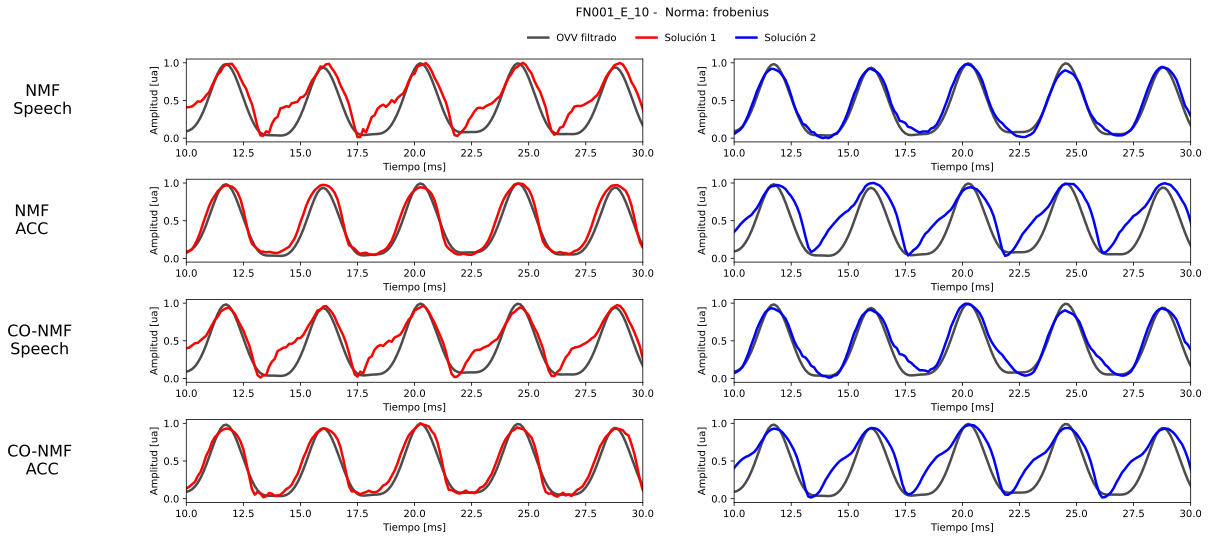

In [ ]:
fig,ax = plt.subplots(4,2,figsize=(18,8))
#fig.suptitle(nombre_archivo.split(".txt")[0] + " | Norma: "+norma, fontsize=12)
plt.subplots_adjust(hspace=0.45)
fontsize = 10
linewidth=2.5
for i in range(0,4):
    for j in range(0,2):
        ax[i][j].plot(tiempos,flujo_ovv,color='k',alpha=0.7,linewidth=linewidth)
        ax[i][j].set_xlim([10,30])
        ax[i][j].set_xlabel("Tiempo [ms]",fontsize=fontsize)
        ax[i][j].set_ylabel("Amplitud [ua]",fontsize=fontsize)

ax[0][0].plot(SP1.tiempos_gve,Funciones.Sincronizar(nmf_flujo1_speech,flujo_ovv),color=color1,label="Solucion 1",linewidth=linewidth)
#ax[0][0].legend(loc='upper right',fontsize=8,ncol=3)
ax[0][1].plot(SP1.tiempos_gve,Funciones.Sincronizar(nmf_flujo2_speech,flujo_ovv),color=color2,label="Solucion 2",linewidth=linewidth)



ax[0][0].annotate("NMF\nSpeech",
                    xy=(-0.25, 0.5), xycoords='axes fraction',
                    fontsize=16,
                    va='center', ha='right',multialignment='center')

ax[1][0].plot(SP2.tiempos_gve,Funciones.Sincronizar(nmf_flujo1_acc,flujo_ovv),color=color1,linewidth=linewidth)
ax[1][1].plot(SP2.tiempos_gve,Funciones.Sincronizar(nmf_flujo2_acc,flujo_ovv),color=color2,linewidth=linewidth)

ax[1][0].annotate("NMF\nACC",
                    xy=(-0.30, 0.5), xycoords='axes fraction',
                    fontsize=16,
                    va='center', ha='right',multialignment='center')

ax[2][0].plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo1_speech,flujo_ovv),color=color1,linewidth=linewidth)
ax[2][1].plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo2_speech,flujo_ovv),color=color2,linewidth=linewidth)

ax[2][0].annotate("CO-NMF\nSpeech",
                    xy=(-0.25, 0.5), xycoords='axes fraction',
                    fontsize=16,
                    va='center', ha='right',multialignment='center')

ax[3][0].plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo1_acc,flujo_ovv),color=color1,linewidth=linewidth)
ax[3][1].plot(SP.tiempos_gve,Funciones.Sincronizar(conmf_flujo2_acc,flujo_ovv),color=color2,linewidth=linewidth);
ax[3][0].annotate("CO-NMF\n ACC",
                    xy=(-0.25, 0.5), xycoords='axes fraction',
                    fontsize=16,
                    va='center', ha='right',multialignment='center');


handles = [
    plt.Line2D([0], [0], color='k', alpha=0.7, label='OVV filtrado',linewidth=linewidth),
    plt.Line2D([0], [0], color=color1, label='Solución 1',linewidth=linewidth),
    plt.Line2D([0], [0], color=color2, label='Solución 2',linewidth=linewidth),
]
'''
fig.legend(handles=handles,
           loc='upper center',
           ncol=3,
           frameon=True,
           fontsize=11,
           bbox_to_anchor=(0.5,0.96));
'''
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.5,y=0.97)

fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.5, 0.94),  # ← misma altura, más a la derecha
           ncol=3,
           frameon=False);
#fig.savefig('Comparacion_'+nombre_archivo+'.pdf',bbox_inches = 'tight');